# Step 3 — Verifying the Hopfield Network

**Project:** *When Memories Compete: How Similarity Affects Memory Retrieval in Hopfield Networks*

The goal of this notebook is to **check that the network works correctly**. It does not draw conclusions about similarity; that is step 4.

Plan, in order:
1. Implement a classical Hopfield network with Hebbian learning (`src/hopfield.py`)
2. **Test A:** the weight matrix is symmetric with a zero diagonal
3. **Test B:** a single stored image is stable
4. **Test C:** a corrupted single image is retrieved
5. **Control:** several *random, uncorrelated* patterns are stored and retrieved correctly
6. **Only if all tests pass:** store the 5-image candidate groups from step 2 and look at what happens

The handwritten digits are strongly correlated (step 2 found an overlap of about 0.45 even between different digits).
The classical theory assumes *uncorrelated* patterns, so the network may struggle with the digit groups **even when the code is correct**.
The control in step 5 is there to tell those two cases apart.

In [2]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Make the project root importable (works whether Jupyter starts in notebooks/ or the root)
project_root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.optdigits import load_optdigits
from src.hopfield import train_hebbian, recall, energy, is_fixed_point, corrupt, overlap

images, labels = load_optdigits()
N = 32 * 32

# Same conversion as notebook 02: 0/1 image -> ±1 vector of 1024 neurons.
# Stored as float64 so no later calculation can overflow.
patterns = (2.0 * images.reshape(len(images), N) - 1.0)
print("patterns:", patterns.shape, patterns.dtype, np.unique(patterns))

def show(ax, vec, title=""):
    """Draw a ±1 vector as a 32x32 image (ink = black)."""
    ax.imshow(vec.reshape(32, 32), cmap="gray_r", vmin=-1, vmax=1)
    ax.set_title(title, fontsize=9)
    ax.axis("off")

rng = np.random.default_rng(2026)   # one seeded generator, so the whole notebook is reproducible

patterns: (946, 1024) float64 [-1.  1.]


## 1. The model (`src/hopfield.py`)

**Neurons.** N = 1024, one per pixel, each in state $s_i \in \{-1, +1\}$.

**Hebbian learning.** To store patterns $\xi^1, \dots, \xi^P$:
$$W_{ij} = \frac{1}{N} \sum_{\mu=1}^{P} \xi_i^\mu \xi_j^\mu \quad (i \neq j), \qquad W_{ii} = 0$$
Two neurons that have the same sign in a stored pattern get a positive (excitatory) connection, and opposite signs give a negative one.

**Recall (asynchronous).** Start from a state $s$. Visit neurons one at a time in random order and set
$$s_i \leftarrow \operatorname{sign}(h_i), \qquad h_i = \sum_j W_{ij} s_j$$
If $h_i = 0$ the neuron keeps its state. Stop when a full sweep over all neurons changes nothing (a **fixed point**).

**Energy.** $E(s) = -\tfrac12 s^\top W s$. If $W$ is symmetric with a zero diagonal, each update can only lower $E$ or keep it the same.
That is why the network is guaranteed to settle, and why Test A matters.

**Measuring retrieval.** The overlap $m = \frac1N \sum_i s_i \xi_i$ from step 2: $m = 1$ means perfect retrieval.

## 2. Test A: the weight matrix

Checks:
1. On a tiny example (4 neurons, 2 patterns), `train_hebbian` matches the formula computed by hand.
2. On a real stored image: $W$ is **symmetric** ($W = W^\top$), has a **zero diagonal**, is float64 and contains no NaN or inf values.

Symmetry and the zero diagonal are what guarantee convergence (see the energy argument above).

In [3]:
test_results = {}   # collects pass/fail for every test, checked before section 6

# --- 1. Tiny hand-checkable example ---
xi1 = np.array([ 1, -1,  1, -1])
xi2 = np.array([ 1,  1, -1, -1])
W_tiny = train_hebbian(np.array([xi1, xi2]))

# Hand calculation: W_ij = (xi1_i*xi1_j + xi2_i*xi2_j) / 4, then zero the diagonal
W_hand = np.zeros((4, 4))
for i in range(4):
    for j in range(4):
        if i != j:
            W_hand[i, j] = (xi1[i] * xi1[j] + xi2[i] * xi2[j]) / 4
print("W (tiny example):\n", W_tiny)
tiny_ok = np.allclose(W_tiny, W_hand)
print("matches hand calculation:", tiny_ok)

# --- 2. Real image ---
W_one = train_hebbian(patterns[0])
checks = {
    "symmetric":          np.array_equal(W_one, W_one.T),
    "zero diagonal":      np.all(np.diag(W_one) == 0),
    "dtype float64":      W_one.dtype == np.float64,
    "all finite":         np.all(np.isfinite(W_one)),
    "shape (1024, 1024)": W_one.shape == (N, N),
}
for name, ok in checks.items():
    print(f"  {name:20s}: {'PASS' if ok else 'FAIL'}")

test_results["A: weights"] = tiny_ok and all(checks.values())
print("\nTest A:", "PASS" if test_results["A: weights"] else "FAIL")

W (tiny example):
 [[ 0.   0.   0.  -0.5]
 [ 0.   0.  -0.5  0. ]
 [ 0.  -0.5  0.   0. ]
 [-0.5  0.   0.   0. ]]
matches hand calculation: True
  symmetric           : PASS
  zero diagonal       : PASS
  dtype float64       : PASS
  all finite          : PASS
  shape (1024, 1024)  : PASS

Test A: PASS


## 3. Test B: a single stored image is stable

Store **one** image and start the network exactly at that image. It should not change.

Why: with one stored pattern $\xi$, the local field is $h_i = \frac{N-1}{N} \xi_i$, which always has the same sign as $\xi_i$, so no neuron flips.

Checks:
- every neuron agrees with its local field (`is_fixed_point` = 1.0)
- running `recall` from the image gives 0 flips (overlap m = 1, converged after 1 sweep)
- repeated for 20 different images, one at a time

As expected from theory, the **inverted** image $-\xi$ is also stable. This "mirror" state is a known property of Hopfield networks, not a bug.

In [4]:
TEST_IMAGES = rng.choice(len(patterns), size=20, replace=False)

single_ok = []
for k in TEST_IMAGES:
    xi = patterns[k]
    W = train_hebbian(xi)
    res = recall(W, xi, rng)
    ok = (is_fixed_point(W, xi) == 1.0) and np.array_equal(res["state"], xi) and res["converged"]
    single_ok.append(ok)

print(f"single-image stability: {sum(single_ok)}/{len(single_ok)} images stable")

# Mirror state check on one image
xi = patterns[TEST_IMAGES[0]]
W = train_hebbian(xi)
print("inverted image also a fixed point:", is_fixed_point(W, -xi) == 1.0)

test_results["B: single image stable"] = all(single_ok)
print("\nTest B:", "PASS" if test_results["B: single image stable"] else "FAIL")

single-image stability: 20/20 images stable
inverted image also a fixed point: True

Test B: PASS


## 4. Test C: retrieving a single image from a corrupted version

Store one image, flip a random fraction of its pixels, and let the network run.
With only one stored pattern, any corruption **below 50%** should be fully repaired (m = 1).
Above 50% the start state is closer to the inverted image, so the network should fall into $-\xi$ instead.

Checks:
- corruption levels 5%, 10%, 20%, 30%, 10 random trials each, should all end at m = 1
- energy never increases during recall
- a 70% corruption control should end at the inverted image (m = −1)

In [5]:
xi = patterns[TEST_IMAGES[0]]
W = train_hebbian(xi)

LEVELS = [0.05, 0.10, 0.20, 0.30]
TRIALS = 10

corruption_ok = True
energy_ok = True
for level in LEVELS:
    final_m = []
    for _ in range(TRIALS):
        start = corrupt(xi, level, rng)
        res = recall(W, start, rng)
        final_m.append(overlap(res["state"], xi))
        # Energy must never go up (allow a tiny floating-point tolerance)
        energy_ok &= np.all(np.diff(res["energies"]) <= 1e-9)
    final_m = np.array(final_m)
    corruption_ok &= np.all(final_m == 1.0)
    print(f"corruption {level:4.0%}: start m = {1 - 2*level:.2f}  ->  final m = {final_m.min():.3f} .. {final_m.max():.3f}")

# Control: >50% corruption should fall into the mirror state
res70 = recall(W, corrupt(xi, 0.70, rng), rng)
mirror_ok = overlap(res70["state"], xi) == -1.0
print(f"corruption  70%: final m = {overlap(res70['state'], xi):.3f}  (expect -1, the inverted image)")
print("energy never increased:", energy_ok)

test_results["C: corrupted single image"] = bool(corruption_ok and energy_ok and mirror_ok)
print("\nTest C:", "PASS" if test_results["C: corrupted single image"] else "FAIL")

corruption   5%: start m = 0.90  ->  final m = 1.000 .. 1.000
corruption  10%: start m = 0.80  ->  final m = 1.000 .. 1.000
corruption  20%: start m = 0.60  ->  final m = 1.000 .. 1.000
corruption  30%: start m = 0.40  ->  final m = 1.000 .. 1.000
corruption  70%: final m = -1.000  (expect -1, the inverted image)
energy never increased: True

Test C: PASS


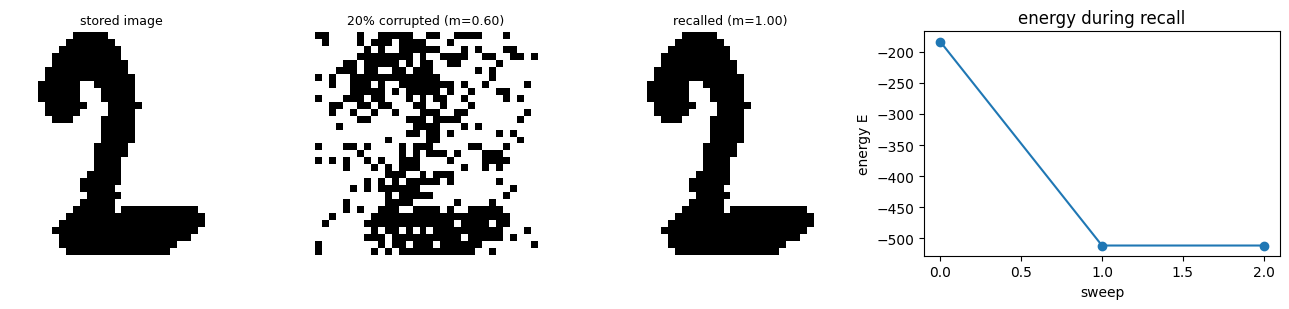

In [6]:
# Picture: original, corrupted (20%), recalled, plus the energy during recall
start = corrupt(xi, 0.20, rng)
res = recall(W, start, rng)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), gridspec_kw={"width_ratios": [1, 1, 1, 1.6]})
show(axes[0], xi, "stored image")
show(axes[1], start, f"20% corrupted (m={overlap(start, xi):.2f})")
show(axes[2], res["state"], f"recalled (m={overlap(res['state'], xi):.2f})")
axes[3].plot(res["energies"], marker="o")
axes[3].set_xlabel("sweep"); axes[3].set_ylabel("energy E"); axes[3].set_title("energy during recall")
plt.tight_layout()
plt.show()

## 5. Control: several random, uncorrelated patterns

Before using digit images, check that the code handles **multiple** stored patterns in the situation the classical theory describes:
patterns made of independent random ±1 values, so their overlaps are near 0.

Five random patterns in N = 1024 neurons is far below the theoretical capacity (about 0.138 N ≈ 141 patterns; Amit, Gutfreund & Sompolinsky, 1985, *Phys. Rev. Lett.* 55, 1530), so all five should be stable and retrievable from 10% corruption.
If this passes, any trouble with the digit groups comes from the **patterns** (their correlations), not from a bug.

In [7]:
P_RANDOM = 5
random_patterns = rng.choice([-1.0, 1.0], size=(P_RANDOM, N))
W_rand = train_hebbian(random_patterns)

M_rand = random_patterns @ random_patterns.T / N
off_diag = M_rand[~np.eye(P_RANDOM, dtype=bool)]
print(f"pairwise overlaps between random patterns: {off_diag.min():.3f} .. {off_diag.max():.3f}  (near 0)")

stable = [is_fixed_point(W_rand, p) for p in random_patterns]
print("fraction of stable neurons per pattern:", np.round(stable, 3))

retrieved = []
for mu, p in enumerate(random_patterns):
    for _ in range(TRIALS):
        res = recall(W_rand, corrupt(p, 0.10, rng), rng)
        retrieved.append(overlap(res["state"], p))
retrieved = np.array(retrieved)
print(f"recall from 10% corruption: final m = {retrieved.min():.3f} .. {retrieved.max():.3f} "
      f"over {len(retrieved)} trials")

test_results["Control: random patterns"] = bool(np.all(np.array(stable) == 1.0) and np.all(retrieved == 1.0))
print("\nControl:", "PASS" if test_results["Control: random patterns"] else "FAIL")

pairwise overlaps between random patterns: -0.041 .. 0.092  (near 0)
fraction of stable neurons per pattern: [1. 1. 1. 1. 1.]
recall from 10% corruption: final m = 1.000 .. 1.000 over 50 trials

Control: PASS


In [8]:
print("Summary of verification tests")
for name, ok in test_results.items():
    print(f"  {name:28s}: {'PASS' if ok else 'FAIL'}")

ALL_TESTS_PASSED = all(test_results.values())
assert ALL_TESTS_PASSED, "Fix the failing test(s) before storing the digit groups."
print("\nAll tests passed: the implementation behaves as theory predicts.")

Summary of verification tests
  A: weights                  : PASS
  B: single image stable      : PASS
  C: corrupted single image   : PASS
  Control: random patterns    : PASS

All tests passed: the implementation behaves as theory predicts.


## 6. Storing the five-image candidate groups

The groups were chosen in notebook 02 (greedy search over typical images, 5 different digits each).
Their indices are copied here, and the labels are checked so a typo can't slip in.

For each group, store all 5 images in one network, then:
1. **Stability:** what fraction of each image's neurons agree with their local field? (1.0 = perfectly stable)
2. **Recall from the clean image:** start exactly at each stored image. Where does the network end up?
   Measure the final state's overlap with **all 5** stored images.
3. **Recall from 10% corruption:** 10 trials per image, overlap with the correct image.

This section only **describes** what the network does. Comparing the groups properly (more groups, noise levels, statistics) is step 4.

In [9]:
assert ALL_TESTS_PASSED   # do not run the group experiments unless the tests above passed

GROUPS = {
    "LOW":  np.array([226, 813, 365, 386, 127]),   # from notebook 02
    "HIGH": np.array([608, 629, 877, 534, 689]),   # from notebook 02
}
assert labels[GROUPS["LOW"]].tolist()  == [4, 2, 9, 7, 6]
assert labels[GROUPS["HIGH"]].tolist() == [1, 8, 2, 3, 5]

results = {}
for name, idx in GROUPS.items():
    stored = patterns[idx]                        # (5, 1024)
    W = train_hebbian(stored)
    assert np.array_equal(W, W.T) and np.all(np.diag(W) == 0)   # Test A again, on this W

    stability = np.array([is_fixed_point(W, p) for p in stored])

    # Recall from each clean image; row mu = start at image mu, column nu = overlap with image nu
    clean_final = []
    clean_overlaps = np.zeros((5, 5))
    for mu, p in enumerate(stored):
        res = recall(W, p, rng)
        clean_final.append(res["state"])
        clean_overlaps[mu] = stored @ res["state"] / N

    # Recall from 10% corruption
    noisy_m = np.zeros((5, TRIALS))
    for mu, p in enumerate(stored):
        for t in range(TRIALS):
            res = recall(W, corrupt(p, 0.10, rng), rng)
            noisy_m[mu, t] = overlap(res["state"], p)

    results[name] = dict(idx=idx, stored=stored, stability=stability,
                         clean_final=np.array(clean_final), clean_overlaps=clean_overlaps, noisy_m=noisy_m)

    digits = labels[idx]
    print(f"===== {name} group: digits {digits.tolist()} =====")
    print("  fraction of stable neurons :", np.round(stability, 3))
    print("  clean start -> final m with own image:", np.round(np.diag(clean_overlaps), 3))
    print("  clean start -> closest stored image  :",
          [int(digits[np.argmax(row)]) for row in clean_overlaps])
    print("  10% corruption -> mean final m      :", np.round(noisy_m.mean(axis=1), 3))
    print()

===== LOW group: digits [4, 2, 9, 7, 6] =====
  fraction of stable neurons : [1.    0.94  0.963 0.942 0.978]
  clean start -> final m with own image: [1.    0.881 0.867 0.879 0.949]
  clean start -> closest stored image  : [4, 2, 9, 7, 6]
  10% corruption -> mean final m      : [0.847 0.881 0.867 0.879 0.949]

===== HIGH group: digits [1, 8, 2, 3, 5] =====
  fraction of stable neurons : [0.949 0.929 0.896 0.862 0.847]
  clean start -> final m with own image: [0.898 0.857 0.793 0.725 0.693]
  clean start -> closest stored image  : [1, 1, 1, 1, 1]
  10% corruption -> mean final m      : [0.898 0.857 0.793 0.725 0.693]



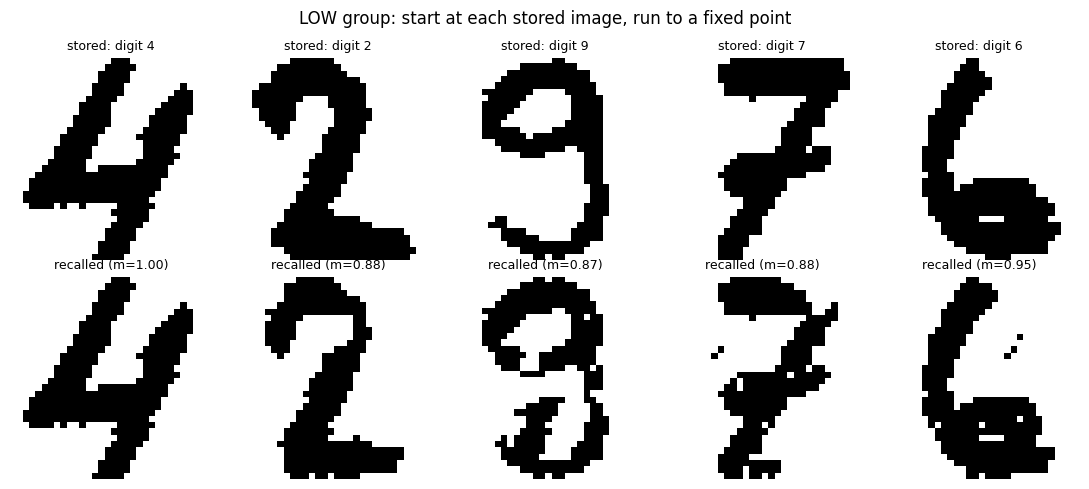

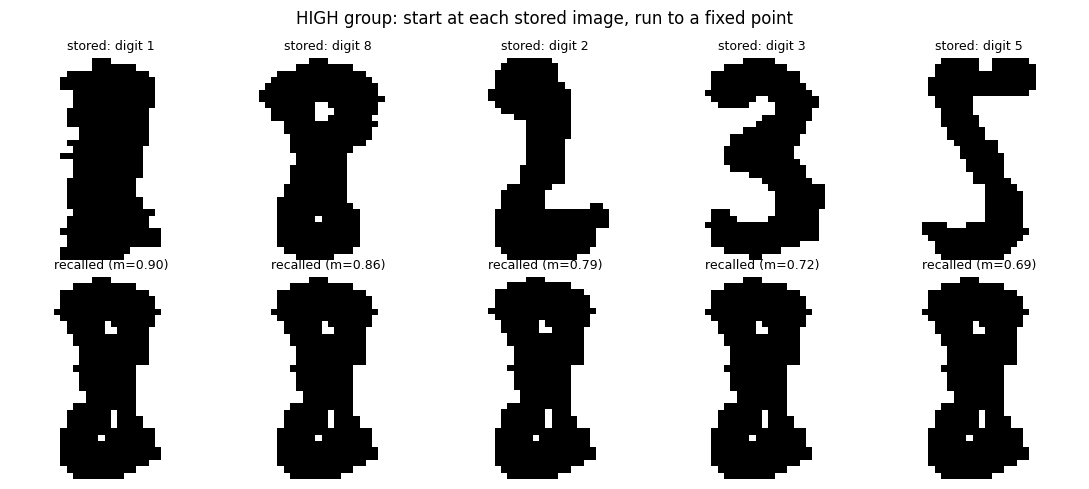

In [10]:
# Pictures: stored images (top) and where recall from each clean image ends up (bottom)
for name, r in results.items():
    fig, axes = plt.subplots(2, 5, figsize=(11, 5))
    for mu in range(5):
        show(axes[0, mu], r["stored"][mu], f"stored: digit {labels[r['idx'][mu]]}")
        show(axes[1, mu], r["clean_final"][mu], f"recalled (m={r['clean_overlaps'][mu, mu]:.2f})")
    fig.suptitle(f"{name} group: start at each stored image, run to a fixed point")
    plt.tight_layout()
    plt.show()

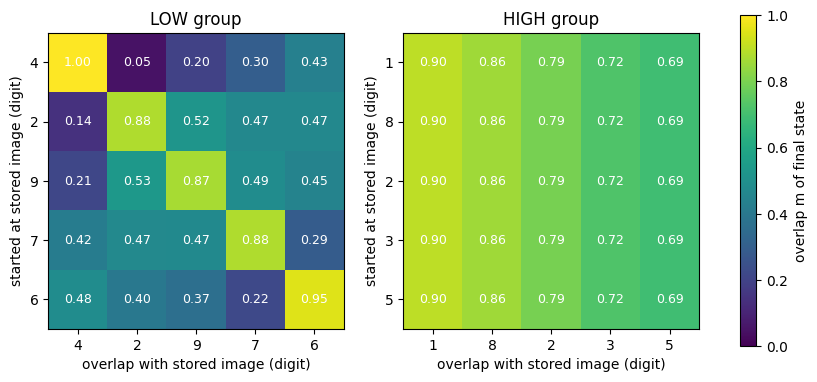

In [11]:
# Overlap of each final state with every stored image
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3))
for ax, (name, r) in zip(axes, results.items()):
    im = ax.imshow(r["clean_overlaps"], cmap="viridis", vmin=0, vmax=1)
    for a in range(5):
        for b in range(5):
            ax.text(b, a, f"{r['clean_overlaps'][a, b]:.2f}", ha="center", va="center", color="white", fontsize=9)
    d = labels[r["idx"]]
    ax.set_xticks(range(5)); ax.set_xticklabels(d)
    ax.set_yticks(range(5)); ax.set_yticklabels(d)
    ax.set_xlabel("overlap with stored image (digit)")
    ax.set_ylabel("started at stored image (digit)")
    ax.set_title(f"{name} group")
fig.colorbar(im, ax=axes, label="overlap m of final state")
plt.show()

## 7. What the outputs show (verification only)

- **Tests A–C and the random-pattern control pass.** The weights have the required structure, a single memory is stable and repairs itself from corruption, energy never increases, and several *uncorrelated* memories are stored without error.
  So the implementation is behaving as the theory says it should.
- **With the digit groups, the stored images are not all perfect fixed points**, even when the network starts exactly at them. The printed stability fractions are below 1.0.
  This is the expected effect of **correlated patterns**. Each image's local field also contains "cross-talk" from the other four images, and when the images overlap strongly that cross-talk can outweigh the image's own contribution.
- Look at the heatmaps above to see **where** recall ends up. A final state that resembles several stored images at once, rather than one of them, is a **mixture / shared attractor**: the memories have merged.

These are **observations from one network per group**, not conclusions yet.
Step 4 can test them systematically: more groups across the full similarity range, several corruption levels, and repeated trials.